# Comment 1-3 — Field inversion sensitivity to the starting value

本 notebook 比較現地移動視窗反演對初始值的敏感度，僅使用現有 `soil_inverse` 模組，**不修改原始模組、既有 notebook 或 Word 檔**。

- **A · Coarse scan + L-BFGS-B**：直接呼叫既有求解器，保留 16 點對數粗掃描、起點比較與既有回退規則。
- **B · Direct L-BFGS-B**：使用相同目標函數、解析梯度、參數範圍與停止設定，但直接從指定起點求解，不粗掃描、不回退。
- 固定 3 小時視窗、1 小時位移、β = 10¹² K² s² m⁻⁴、prior = 10⁻⁶ m²/s；指定初始值為 10⁻⁸、10⁻⁷、5×10⁻⁷、10⁻⁶、5×10⁻⁶、10⁻⁵ m²/s。

此實驗檢查**固定正則化設定下的數值起點敏感度**，不證明 β／prior 最佳、物理參數唯一或找到全域最小值。不同初始值是同一組資料的數值重複計算，不是獨立觀測。

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, time
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.ticker as ticker
from scipy.optimize import minimize, minimize_scalar
from IPython.display import display, Markdown

# Works when opened from the project root or another directory inside this project.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'soil_inverse').is_dir() and (p / 'Lupit_20210729_0812.csv').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook inside soil_temperature_inverse_problem.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from soil_inverse import HeatGrid, TikhonovRegularization, load_and_resample_soil_csv
from soil_inverse import make_window_indices, solve_adjoint_gradient_descent
from soil_inverse.objective import evaluate_cost

OUTPUT_DIR = ROOT / '00_output_figures/06_comment_1_3_initial_value_sensitivity'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATH = ROOT / 'Lupit_20210729_0812.csv'
TEMP_COLUMNS = ['T1', 'T2', 'T3', 'T4']
WATER_COLUMNS = ['M1', 'M2', 'M3', 'M4']
DEPTHS_M = np.array([0.25, 0.50, 0.75, 1.00])
START = pd.Timestamp('2021-07-29 12:00')
END = pd.Timestamp('2021-08-12 00:00')
EVENT_START, EVENT_END = pd.Timestamp('2021-08-06'), pd.Timestamp('2021-08-09')
WINDOW_HOURS, STRIDE_HOURS = 3.0, 1.0
ALPHA_INITIALS = np.array([1e-8, 1e-7, 5e-7, 1e-6, 5e-6, 1e-5])
BOUNDS = (1e-8, 1e-5)
PRIOR, BETA = 1e-6, 1e12
# MAX_ITER and FTOL mirror hard-coded settings in the unchanged A solver.
N_SCAN, MAX_ITER, GTOL, FTOL = 16, 60, 1e-8, 1e-12
assert MAX_ITER == 60 and FTOL == 1e-12, "Keep B consistent with the original A solver"
REG = TikhonovRegularization(beta=BETA, prior=PRIOR)
# Reporting thresholds, not optimizer tolerances or statistical significance tests.
ALPHA_REL_TOL = 0.01  # flag >1% difference in fitted alpha
COST_ATOL, COST_RTOL = 1e-8, 1e-6
BOUND_RTOL = 1e-6
MAX_WINDOWS = None  # None = all windows; a number is for a clearly labelled smoke run only.

plt.rcParams['text.usetex'] = False
plt.rcParams['mathtext.fontset'] = 'cm'
plt.rcParams['font.family'] = 'Times New Roman'
plt.rcParams['figure.dpi'] = 110
COLORS = ['royalblue', 'brown', 'green', 'tomato', 'darkviolet', 'black']
STYLES = ['-', '--', '-.', ':', (0, (5, 2)), (0, (3, 1, 1, 1))]
MODE_LABELS = {'A': 'Coarse scan + L-BFGS-B', 'B': 'Direct L-BFGS-B'}

def style_axis(ax, panel=None, dates=False):
    ax.tick_params(axis='both', labelsize=13)
    ax.grid(True, which='major', color='gray', alpha=0.6, linewidth=0.8)
    ax.grid(True, which='minor', color='lightgray', alpha=0.5, linewidth=0.4, linestyle='--')
    if panel:
        ax.text(0.02, 0.96, '(' + panel + ')', transform=ax.transAxes,
                ha='left', va='top', fontsize=18,
                bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))
    if dates:
        ax.xaxis.set_major_locator(mdates.DayLocator(interval=2))
        ax.xaxis.set_minor_locator(mdates.HourLocator(byhour=[12]))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%m/%d'))

def save_figure(fig, stem):
    fig.savefig(OUTPUT_DIR / (stem + '.jpg'), dpi=400, bbox_inches='tight')
    fig.savefig(OUTPUT_DIR / (stem + '.pdf'), bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 1. Data and fixed forward model

沿用既有主分析：10 分鐘平均重採樣、缺值按時間線性插值；上下測點為 Dirichlet 邊界，內部兩測點為目標。首時刻的溫度沿深度線性插值。網格 Δz = 0.05 m、Crank–Nicolson θ = 0.5。

視窗包含首尾時間點；完整 3 小時視窗共有 19 筆溫度記錄（18 個推進步）。初始時刻的內部殘差為零。RMSE 同時輸出包含首時刻及排除首時刻版本；主要比較使用排除首時刻版本。

In [2]:
times_all, temps_all, _, _ = load_and_resample_soil_csv(
    CSV_PATH, TEMP_COLUMNS, WATER_COLUMNS, resample_interval='10min')
mask = (pd.to_datetime(times_all) >= START) & (pd.to_datetime(times_all) <= END)
times, temps = times_all[mask], temps_all[mask]
assert np.isfinite(temps).all(), 'Non-finite temperature after preprocessing'
dt = np.diff(pd.DatetimeIndex(times).asi8) / 1e9
assert np.allclose(dt, 600.0), 'The forward model requires regular 600 s steps'
grid = HeatGrid(DEPTHS_M, dt_seconds=600.0, cells_per_gap=5, theta=0.5)
windows = make_window_indices(times, WINDOW_HOURS, STRIDE_HOURS, min_points=4)
if MAX_WINDOWS is not None:
    windows = windows[:MAX_WINDOWS]
assert all(len(idx) == 19 for idx in windows)
print(f'{times[0]} → {times[-1]} | {len(windows)} windows | {grid}')
print(f'Expected solves: {len(windows) * len(ALPHA_INITIALS) * 2}')

2021-07-29 12:00:00 → 2021-08-11 23:50:00 | 321 windows | HeatGrid(n_cells=15, dz_m=0.0500, dt_seconds=600, theta=0.5)
Expected solves: 3852


## 2. Controlled starting-value experiment

目標函數為 $J=\frac12\sum e^2+\frac{\beta}{2}(\alpha-\alpha_{prior})^2$，最佳化變數為 $m=\log\alpha$，梯度為 $\partial J/\partial m=\alpha\,\partial J/\partial\alpha$。

A 組直接呼叫原求解器；從其首筆梯度評估讀取真正起點。原函式的 `success` 和 `nit` 屬於局部最佳化器，即使回傳值採用粗掃描回退也仍保留該狀態；原函式未回傳停止訊息或回退旗標，本實驗不臆測這些欄位。B 組完整保存 SciPy 的停止訊息與投影梯度，不作回退。

`gtol` 是 log-space 投影梯度停止條件，`ftol` 是目標函數相對下降停止條件；到达迭代上限不等於成功。邊界上的成功停止也不代表找到最佳可行解。

In [3]:
def solve_direct(obs, alpha_initial):
    def fun(m):
        a = float(np.exp(m[0]))
        c, ga = evaluate_cost(grid, a, obs, reg=REG, with_grad=True)
        return c, np.array([ga * a])
    m0 = float(np.clip(np.log(alpha_initial), *np.log(BOUNDS)))
    res = minimize(fun, np.array([m0]), jac=True, method='L-BFGS-B',
                   bounds=[tuple(np.log(BOUNDS))],
                   options={'gtol': GTOL, 'ftol': FTOL, 'maxiter': MAX_ITER})
    return dict(alpha=float(np.exp(res.x[0])), cost=float(res.fun),
                nit=int(res.nit), nfev=int(res.nfev), success=bool(res.success),
                actual_start=float(np.exp(m0)), message=str(res.message), status=int(res.status))

# Numerical check of the shared objective/gradient before the full experiment.
check_obs = temps[windows[len(windows)//2]]
check_m, h = np.log(7e-7), 1e-5
_, ga = evaluate_cost(grid, np.exp(check_m), check_obs, REG, with_grad=True)
cp = evaluate_cost(grid, np.exp(check_m+h), check_obs, REG)[0]
cm = evaluate_cost(grid, np.exp(check_m-h), check_obs, REG)[0]
assert np.isclose(ga*np.exp(check_m), (cp-cm)/(2*h), rtol=1e-4, atol=1e-7)
# Known-solution check: noiseless constant-alpha data, with matching prior.
synthetic = check_obs.copy()
synthetic[:, 1:3] = grid.simulate(PRIOR, check_obs)['prediction']
known = solve_direct(synthetic, 5e-7)
assert known['success'] and np.isclose(known['alpha'], PRIOR, rtol=1e-4)
print('Gradient finite-difference check and known constant-alpha recovery passed.')

Gradient finite-difference check and known constant-alpha recovery passed.


In [4]:
rows = []
t0 = time.perf_counter()
for window_id, idx in enumerate(windows):
    obs = temps[idx]
    for mode in ['A', 'B']:
        for initial in ALPHA_INITIALS:
            if mode == 'A':
                result = solve_adjoint_gradient_descent(obs, grid, alpha_initial=float(initial),
                    bounds=BOUNDS, reg=REG, n_scan=N_SCAN, gtol=GTOL)
                result['actual_start'] = float(result['history'][0, 1])
                result['message'] = 'Not exposed by original solver; success refers to local optimizer'
                result['status'] = np.nan
            else:
                result = solve_direct(obs, float(initial))
            alpha = result['alpha']
            pred = grid.simulate(alpha, obs)['prediction']
            residual = pred - obs[:, 1:3]
            jd = 0.5 * float(np.sum(residual**2))
            jr = REG.value(alpha)
            _, ga = evaluate_cost(grid, alpha, obs, REG, with_grad=True)
            gm = float(ga * alpha)
            m = np.log(alpha)
            # Unit-step projected gradient mapping, suitable for box constraints.
            pg = float(m - np.clip(m-gm, *np.log(BOUNDS)))
            assert np.isclose(result['cost'], jd+jr, rtol=1e-10, atol=1e-12)
            rows.append(dict(mode=mode, window=window_id, start=times[idx[0]],
                center=times[idx[len(idx)//2]], end=times[idx[-1]], n_samples=len(idx),
                alpha_initial=float(initial), actual_start=result['actual_start'], alpha=alpha,
                initial_replaced=not np.isclose(result['actual_start'], initial, rtol=1e-8, atol=0),
                cost=jd+jr, cost_data=jd, cost_reg=jr,
                rmse_all=float(np.sqrt(np.mean(residual**2))),
                rmse_dynamic=float(np.sqrt(np.mean(residual[1:]**2))),
                success=result['success'], nit=result['nit'], nfev=result['nfev'],
                at_lower=bool(np.isclose(alpha, BOUNDS[0], rtol=BOUND_RTOL, atol=0)),
                at_upper=bool(np.isclose(alpha, BOUNDS[1], rtol=BOUND_RTOL, atol=0)),
                grad_log=gm, projected_grad_log=pg,
                message=result['message'], status=result['status']))
    if (window_id+1) % 50 == 0 or window_id+1 == len(windows):
        print(f'{window_id+1}/{len(windows)} windows; {time.perf_counter()-t0:.1f} s', flush=True)
results = pd.DataFrame(rows)
assert len(results) == len(windows)*len(ALPHA_INITIALS)*2
assert np.isfinite(results[['alpha','cost','rmse_dynamic']].to_numpy()).all()
assert not results.duplicated(['mode','window','alpha_initial']).any()
# This reference is only the lowest-cost solution observed among the tested starts/modes.
refs = results.loc[results.groupby('window')['cost'].idxmin(), ['window','alpha','cost']].rename(
    columns={'alpha':'best_observed_alpha','cost':'best_observed_cost'})
results = results.merge(refs, on='window', how='left')
results['alpha_rel_diff'] = abs(results.alpha-results.best_observed_alpha)/results.best_observed_alpha
results['cost_gap'] = results.cost-results.best_observed_cost
results['higher_cost'] = results.cost_gap > COST_ATOL+COST_RTOL*abs(results.best_observed_cost)
results['alpha_disagreement'] = results.alpha_rel_diff > ALPHA_REL_TOL
results.to_csv(OUTPUT_DIR/'initial_value_detail.csv', index=False)

50/321 windows; 5.9 s
100/321 windows; 11.8 s
150/321 windows; 16.8 s
200/321 windows; 21.4 s
250/321 windows; 27.1 s
300/321 windows; 31.6 s
321/321 windows; 33.5 s


## 3. Summary and numerical sensitivity flags

相對差異的分母為該窗所有受測方法／起點中「最低 cost 解」的 α。這是比較基準，不是已證明的全域解。1% 差異門檻只是預先指定的報告尺度；同时保留連續差異量供判讀。

In [5]:
summary = results.groupby(['mode','alpha_initial']).agg(
    n_windows=('window','size'), success_rate=('success','mean'),
    start_replaced_rate=('initial_replaced','mean'), mean_alpha=('alpha','mean'),
    median_rmse=('rmse_dynamic','median'), mean_nit=('nit','mean'),
    lower_bound_rate=('at_lower','mean'), upper_bound_rate=('at_upper','mean'),
    alpha_disagreement_rate=('alpha_disagreement','mean'), higher_cost_rate=('higher_cost','mean'),
    max_relative_difference=('alpha_rel_diff','max')).reset_index()
spread = results.groupby(['mode','window']).agg(center=('center','first'),
    min_alpha=('alpha','min'), max_alpha=('alpha','max'),
    reference_alpha=('best_observed_alpha','first'), all_success=('success','all'),
    any_higher_cost=('higher_cost','any')).reset_index()
spread['relative_spread'] = (spread.max_alpha-spread.min_alpha)/spread.reference_alpha
summary.to_csv(OUTPUT_DIR/'initial_value_summary.csv', index=False)
spread.to_csv(OUTPUT_DIR/'window_start_spread.csv', index=False)
display(summary)
for mode in ['A','B']:
    s = spread[spread['mode']==mode]
    print(f'{MODE_LABELS[mode]}: {(s.relative_spread>ALPHA_REL_TOL).sum()}/{len(s)} windows '
          f'with >1% between-start spread; maximum = {s.relative_spread.max():.3%}')
failures = results[~results.success].copy()
failures.to_csv(OUTPUT_DIR/'unsuccessful_local_solves.csv', index=False)
results[results.higher_cost].to_csv(OUTPUT_DIR/'higher_cost_solutions.csv', index=False)
termination_summary = results.groupby(['mode','success','message']).size().reset_index(name='n_solves')
termination_summary.to_csv(OUTPUT_DIR/'termination_summary.csv', index=False)
display(termination_summary)


Coarse scan + L-BFGS-B: 0/321 windows with >1% between-start spread; maximum = 0.000%
Direct L-BFGS-B: 2/321 windows with >1% between-start spread; maximum = 99.323%


,mode,alpha_initial,n_windows,success_rate,start_replaced_rate,mean_alpha,median_rmse,mean_nit,lower_bound_rate,upper_bound_rate,alpha_disagreement_rate,higher_cost_rate,max_relative_difference
0,A,1.000000e-08,321,0.959502,0.996885,6.568784e-07,0.075831,4.844237,0.003115,False,0.000000,0.000000,6.213819e-07
1,A,1.000000e-07,321,0.959502,0.996885,6.568784e-07,0.075831,4.844237,0.003115,False,0.000000,0.000000,6.213819e-07
2,A,5.000000e-07,321,0.959502,0.775701,6.568784e-07,0.075831,4.676012,0.003115,False,0.000000,0.000000,6.213819e-07
3,A,1.000000e-06,321,0.959502,0.769470,6.568784e-07,0.075831,4.844237,0.003115,False,0.000000,0.000000,6.213819e-07
4,A,5.000000e-06,321,0.959502,1.000000,6.568784e-07,0.075831,4.844237,0.003115,False,0.000000,0.000000,6.213819e-07
5,A,1.000000e-05,321,0.959502,1.000000,6.568784e-07,0.075831,4.844237,0.003115,False,0.000000,0.000000,6.213819e-07
6,B,1.000000e-08,321,0.968847,0.000000,6.485686e-07,0.075831,5.725857,0.006231,False,0.006231,0.006231,9.932285e-01
7,B,1.000000e-07,321,0.959502,0.000000,6.485686e-07,0.075831,6.644860,0.006231,False,0.006231,0.006231,9.932285e-01
8,B,5.000000e-07,321,0.962617,0.000000,6.568784e-07,0.075831,5.862928,0.003115,False,0.000000,0.000000,1.736364e-06
9,B,1.000000e-06,321,0.962617,0.000000,6.568784e-07,0.075831,5.750779,0.003115,False,0.000000,0.000000,9.420581e-07


,mode,success,message,n_solves
0,A,False,Not exposed by original solver; success refers...,78
1,A,True,Not exposed by original solver; success refers...,1848
2,B,False,ABNORMAL_TERMINATION_IN_LNSRCH,65
3,B,True,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,1566
4,B,True,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH,295


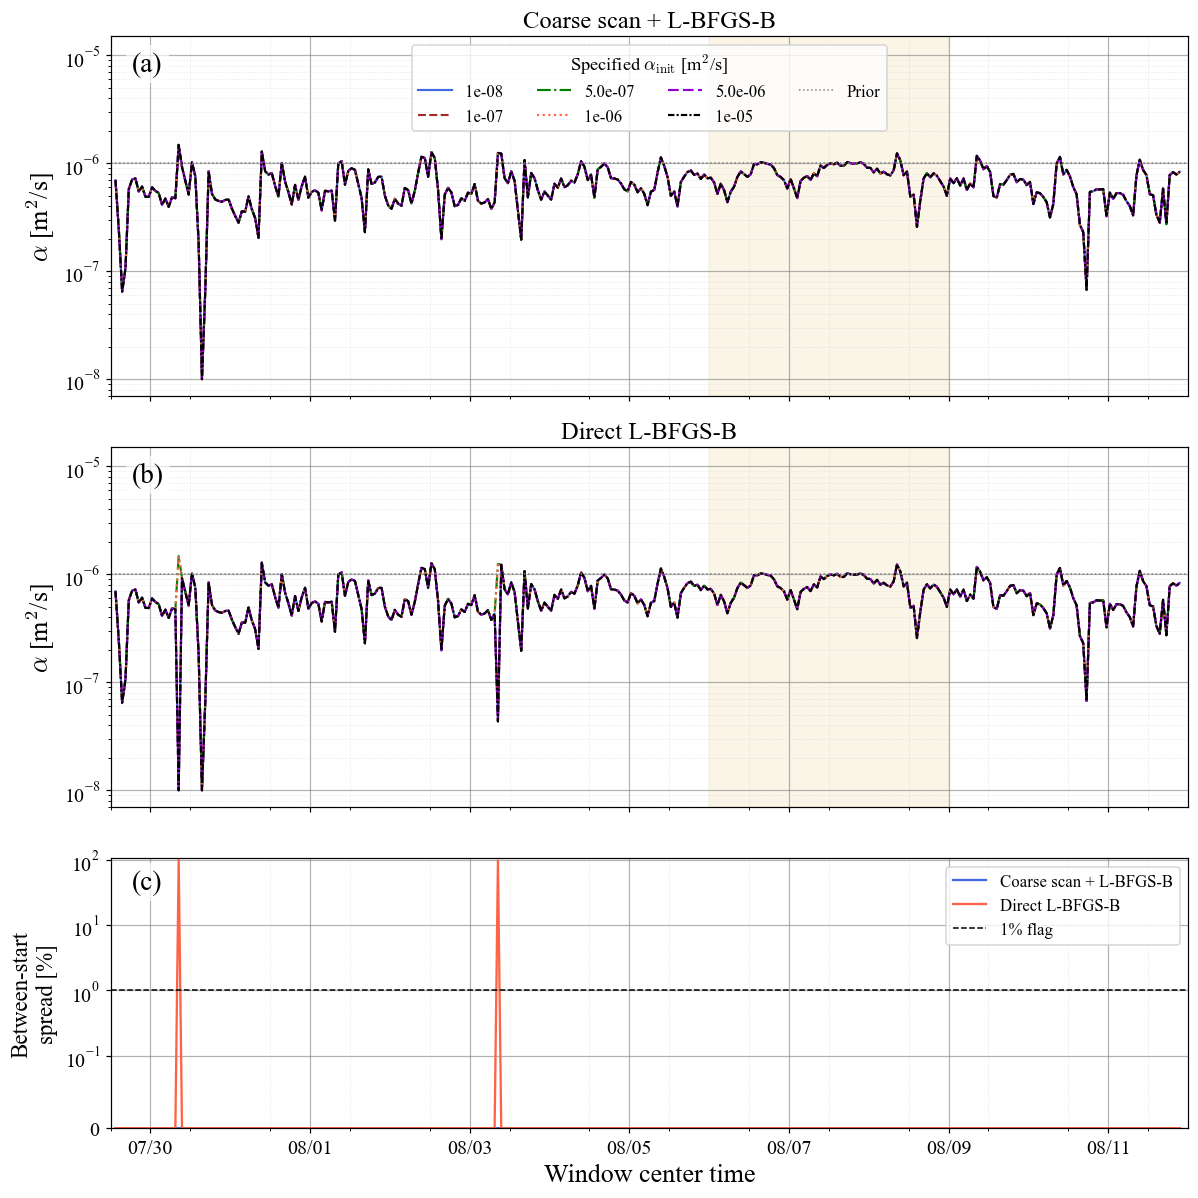

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(11, 11), sharex=True,
                         gridspec_kw={'height_ratios':[1,1,0.75]})
for ax, mode, panel in zip(axes[:2], ['A','B'], ['a','b']):
    for initial, color, ls in zip(ALPHA_INITIALS, COLORS, STYLES):
        sub = results[(results['mode']==mode)&(results.alpha_initial==initial)].sort_values('center')
        ax.plot(sub.center, sub.alpha, color=color, linestyle=ls, linewidth=1.4,
                label=f'{initial:.0e}' if initial in [1e-8,1e-7,1e-6,1e-5] else f'{initial:.1e}')
    ax.axhline(PRIOR, color='gray', linewidth=1, linestyle=':', label='Prior')
    ax.set_yscale('log'); ax.set_ylim(7e-9, 1.5e-5)
    ax.set_ylabel(r'$\alpha$ [m$^2$/s]', fontsize=17)
    ax.set_title(MODE_LABELS[mode], fontsize=16)
    ax.axvspan(EVENT_START, EVENT_END, color='goldenrod', alpha=0.10)
    style_axis(ax, panel, dates=True)
axes[0].legend(title=r'Specified $\alpha_{\rm init}$ [m$^2$/s]', ncol=4,
               fontsize=11, title_fontsize=12, loc='upper center')
for mode, color in [('A','royalblue'),('B','tomato')]:
    sub = spread[spread['mode']==mode].sort_values('center')
    axes[2].plot(sub.center, 100*sub.relative_spread, color=color, linewidth=1.5, label=MODE_LABELS[mode])
axes[2].axhline(100*ALPHA_REL_TOL, color='black', linestyle='--', linewidth=1, label='1% flag')
axes[2].set_yscale('symlog', linthresh=0.1)
axes[2].set_ylim(bottom=0)
axes[2].set_ylabel('Between-start\nspread [%]', fontsize=15)
axes[2].set_xlabel('Window center time', fontsize=17)
axes[2].legend(fontsize=11, loc='upper right')
style_axis(axes[2], 'c', dates=True)
axes[2].set_xlim(START, END)
fig.tight_layout(h_pad=1.3)
save_figure(fig, 'initial_value_timeseries')

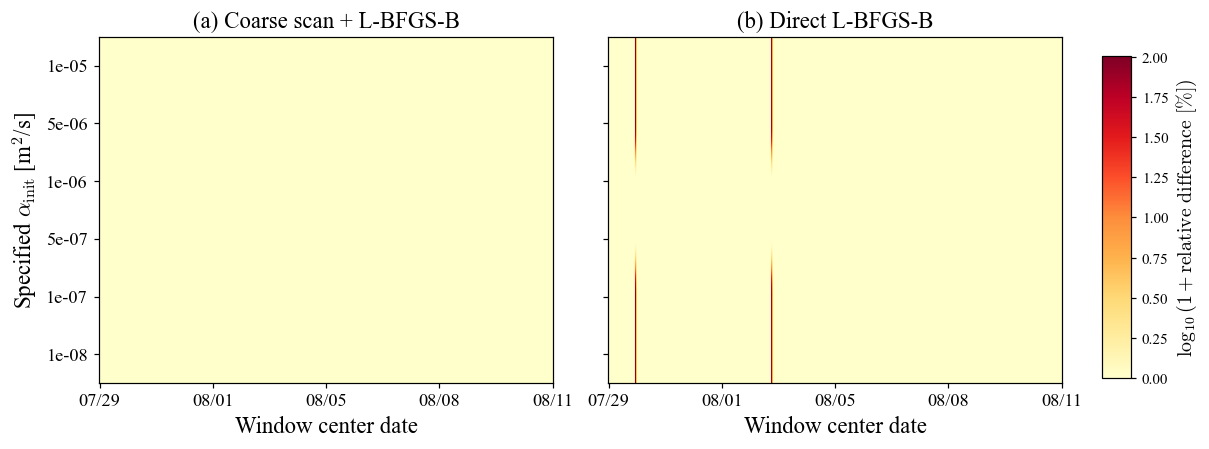

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, mode, panel in zip(axes, ['A','B'], ['a','b']):
    mat = results[results['mode']==mode].pivot(index='alpha_initial', columns='window', values='alpha_rel_diff')
    im = ax.imshow(np.log10(1 + 100*mat.to_numpy()), aspect='auto', origin='lower',
                   cmap='YlOrRd', vmin=0, vmax=np.log10(1+100*results.alpha_rel_diff.max()))
    ax.set_yticks(np.arange(len(ALPHA_INITIALS)))
    ax.set_yticklabels([f'{a:.0e}' for a in ALPHA_INITIALS])
    tickpos = np.unique(np.linspace(0,len(windows)-1,min(5,len(windows))).astype(int))
    centers = spread[spread['mode']==mode].sort_values('window').center
    ax.set_xticks(tickpos)
    ax.set_xticklabels([pd.Timestamp(centers.iloc[i]).strftime('%m/%d') for i in tickpos])
    ax.set_xlabel('Window center date', fontsize=15)
    ax.set_title(f'({panel}) {MODE_LABELS[mode]}', fontsize=15)
    ax.tick_params(labelsize=12)
axes[0].set_ylabel(r'Specified $\alpha_{\rm init}$ [m$^2$/s]', fontsize=15)
fig.subplots_adjust(left=0.09, right=0.82, bottom=0.17, top=0.87, wspace=0.12)
cax=fig.add_axes([0.85,0.18,0.022,0.65])
cbar=fig.colorbar(im,cax=cax)
cbar.set_label(r'$\log_{10}(1+\mathrm{relative\ difference\ [\%]})$',fontsize=13)
save_figure(fig, 'initial_value_difference_heatmap')

## 4. Objective profiles for the most sensitive windows

選擇 B 組起點間差異最大的三個視窗，掃描完整參數範圍（401 點），再細化掃描中的各局部極小值。此圖用於辨識較差邊界解、不同局部極小值或平坦區域；有限網格掃描仍不構成全域最優證明。灰色叉號標示指定起點，圓點標示最終值，向下三角形標示細掃描所得最低 cost 候選值。

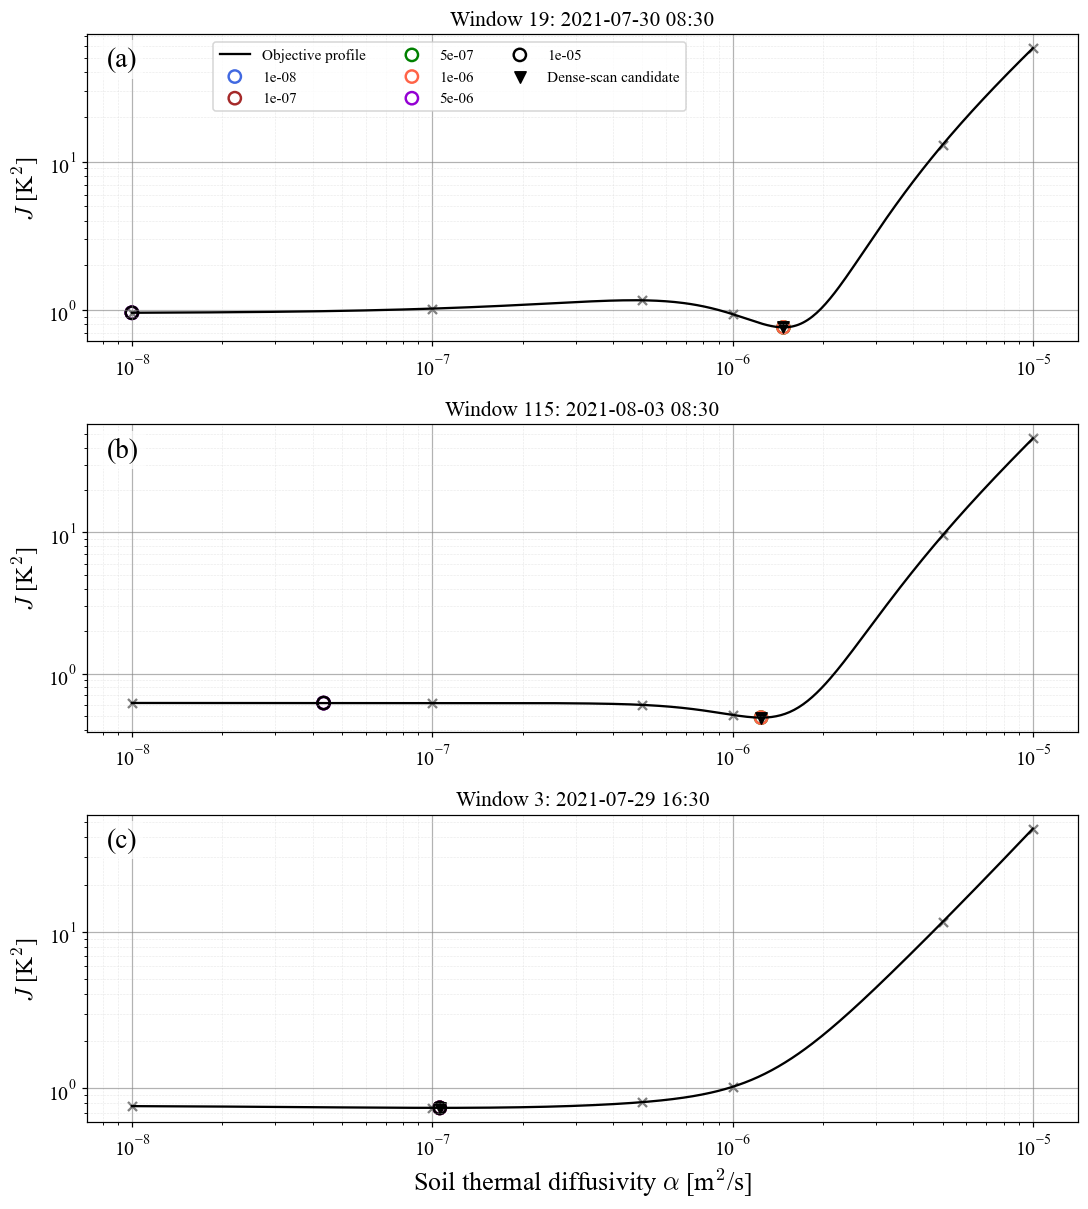

,window,dense_refined_alpha,dense_refined_cost
0,19,1.476771e-06,0.762621
1,115,1.244174e-06,0.487959
2,3,1.059044e-07,0.749632


In [8]:
worst = spread[spread['mode']=='B'].nlargest(min(3,len(windows)), 'relative_spread')['window'].tolist()
profile_rows, diagnostic_rows = [], []
fig, axes = plt.subplots(len(worst), 1, figsize=(10, 3.7*len(worst)), squeeze=False)
for ax, wid, panel in zip(axes[:,0], worst, ['a','b','c']):
    obs = temps[windows[int(wid)]]
    ms = np.linspace(*np.log(BOUNDS), 401)
    costs = np.array([evaluate_cost(grid,np.exp(m),obs,REG)[0] for m in ms])
    candidates = [(float(costs[0]),float(ms[0])), (float(costs[-1]),float(ms[-1]))]
    for k in range(1,len(ms)-1):
        if costs[k]<=costs[k-1] and costs[k]<=costs[k+1]:
            rr=minimize_scalar(lambda m:evaluate_cost(grid,np.exp(m),obs,REG)[0],
                bounds=(ms[k-1],ms[k+1]),method='bounded',options={'xatol':1e-12})
            candidates.append((float(rr.fun),float(rr.x)))
    best_cost,best_m=min(candidates)
    diagnostic_rows.append(dict(window=wid, dense_refined_alpha=np.exp(best_m), dense_refined_cost=best_cost))
    profile_rows.extend(dict(window=wid,alpha=np.exp(m),cost=c) for m,c in zip(ms,costs))
    ax.plot(np.exp(ms), costs, color='black', linewidth=1.5, label='Objective profile')
    for initial,color in zip(ALPHA_INITIALS,COLORS):
        r=results[(results['mode']=='B')&(results.window==wid)&(results.alpha_initial==initial)].iloc[0]
        ax.scatter(initial,evaluate_cost(grid,initial,obs,REG)[0],marker='x',color='gray',s=35)
        ax.scatter(r.alpha,r.cost,s=65,facecolors='none',edgecolors=color,linewidths=1.6,label=f'{initial:.0e}')
    ax.scatter(np.exp(best_m),best_cost,marker='v',color='black',s=55,label='Dense-scan candidate')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_ylabel(r'$J$ [K$^2$]',fontsize=16)
    center=results[results.window==wid].center.iloc[0]
    ax.set_title(f'Window {wid}: {pd.Timestamp(center):%Y-%m-%d %H:%M}',fontsize=14)
    style_axis(ax,panel)
axes[-1,0].set_xlabel(r'Soil thermal diffusivity $\alpha$ [m$^2$/s]',fontsize=17)
axes[0,0].legend(ncol=3,fontsize=10,loc='upper left',bbox_to_anchor=(0.12,1.0))
fig.tight_layout(h_pad=1.4)
save_figure(fig,'initial_value_objective_profiles')
pd.DataFrame(profile_rows).to_csv(OUTPUT_DIR/'objective_profile_detail.csv',index=False)
pd.DataFrame(diagnostic_rows).to_csv(OUTPUT_DIR/'objective_profile_refined_minima.csv',index=False)
display(pd.DataFrame(diagnostic_rows))

## 5. Reproducibility record and interpretation

所有輸出只寫入本次新資料夾。軟體版本與雜湊記錄的是本次執行環境，不代表原稿歷史執行環境。每次執行都重新計算，不讀取舊結果快取。

In [9]:
source_paths=[CSV_PATH,*sorted((ROOT/'soil_inverse').glob('*.py'))]
manifest=dict(python=sys.version,numpy=np.__version__,scipy=scipy.__version__,
    pandas=pd.__version__,matplotlib=matplotlib.__version__,platform=platform.platform(),
    period=[str(START),str(END)],actual_data_period=[str(times[0]),str(times[-1])],window_hours=WINDOW_HOURS,stride_hours=STRIDE_HOURS,
    alpha_initials=ALPHA_INITIALS.tolist(),alpha_bounds=list(BOUNDS),alpha_prior=PRIOR,
    beta=BETA,beta_units='K^2 s^2 m^-4',n_scan=N_SCAN,max_iter=MAX_ITER,gtol=GTOL,ftol=FTOL,
    delta_z_m=grid.dz_m,delta_t_seconds=grid.dt_seconds,theta=grid.theta,
    n_windows=len(windows),n_solves=len(results),max_windows=MAX_WINDOWS,
    report_alpha_relative_tolerance=ALPHA_REL_TOL,cost_atol=COST_ATOL,cost_rtol=COST_RTOL,
    sources={str(p.relative_to(ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in source_paths})
(OUTPUT_DIR/'run_manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
lines=['# Comment 1-3 starting-value test results','',
       f'Executed {len(results)} solves across {len(windows)} field windows and six starting values.',
       '', 'Fixed beta = 1e12 K^2 s^2 m^-4; prior = 1e-6 m^2/s.']
for mode in ['A','B']:
    s=spread[spread['mode']==mode]; r=results[results['mode']==mode]
    lines += ['',f'## {MODE_LABELS[mode]}',
        f'- Windows with >1% between-start spread: {int((s.relative_spread>ALPHA_REL_TOL).sum())}/{len(s)}.',
        f'- Maximum relative spread: {100*s.relative_spread.max():.6g}%.',
        f'- Local optimizer unsuccessful: {int((~r.success).sum())}/{len(r)} solves, involving {r.loc[~r.success, "window"].nunique()} windows.',
        f'- Lower/upper bound solutions: {int(r.at_lower.sum())}/{int(r.at_upper.sum())}.',
        f'- Solutions with higher cost than the best observed: {int(r.higher_cost.sum())}/{len(r)}.',
        f'- Specified starting value replaced: {int(r.initial_replaced.sum())}/{len(r)}.']
lines += ['', '## Interpretation',
    'In this executed comparison, use the counts above to assess robustness. Do not describe every solve as converged when unsuccessful flags are present.',
    'Agreement in A may result from coarse-scan initialization. Compare B before claiming starting-value independence.',
    'Solver success alone does not establish a global minimum. Inspect bound solutions and objective profiles.',
    'The best-observed solution is a numerical comparison reference, not independently known truth.',
    'These tests hold beta and prior fixed; their suitability and sensitivity require separate assessment.',
    'A uses the original solver including its fallback behavior; its success flag refers to the local optimizer.',
    'All relative-spread flags use a descriptive 1% threshold, not a statistical significance test.']
report='\n'.join(lines)+'\n'
(OUTPUT_DIR/'results_summary.md').write_text(report,encoding='utf-8')
display(Markdown(report))
print('Outputs:',OUTPUT_DIR)

Outputs: /Users/ian/Documents/soil_temperature_inverse_problem/00_output_figures/06_comment_1_3_initial_value_sensitivity


# Comment 1-3 starting-value test results

Executed 3852 solves across 321 field windows and six starting values.

Fixed beta = 1e12 K^2 s^2 m^-4; prior = 1e-6 m^2/s.

## Coarse scan + L-BFGS-B
- Windows with >1% between-start spread: 0/321.
- Maximum relative spread: 2.44676e-05%.
- Local optimizer unsuccessful: 78/1926 solves, involving 18 windows.
- Lower/upper bound solutions: 6/0.
- Solutions with higher cost than the best observed: 0/1926.
- Specified starting value replaced: 1778/1926.

## Direct L-BFGS-B
- Windows with >1% between-start spread: 2/321.
- Maximum relative spread: 99.3228%.
- Local optimizer unsuccessful: 65/1926 solves, involving 60 windows.
- Lower/upper bound solutions: 10/0.
- Solutions with higher cost than the best observed: 8/1926.
- Specified starting value replaced: 0/1926.

## Interpretation
In this executed comparison, use the counts above to assess robustness. Do not describe every solve as converged when unsuccessful flags are present.
Agreement in A may result from coarse-scan initialization. Compare B before claiming starting-value independence.
Solver success alone does not establish a global minimum. Inspect bound solutions and objective profiles.
The best-observed solution is a numerical comparison reference, not independently known truth.
These tests hold beta and prior fixed; their suitability and sensitivity require separate assessment.
A uses the original solver including its fallback behavior; its success flag refers to the local optimizer.
All relative-spread flags use a descriptive 1% threshold, not a statistical significance test.
